In [54]:
# Load the libraries used in this analysis
import pandas as pd               # to read and work with the data table
import numpy as np                # for number calculations (used for the trendline)
import matplotlib.pyplot as plt   # basic charts
import seaborn as sns             # charts with a cleaner style
import plotly.express as px       # interactive charts

# Read the Excel file into a DataFrame called df
df = pd.read_excel('applications.xlsx')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17339 entries, 0 to 17338
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   Applicant              17339 non-null  int64
 1   Sex                    17339 non-null  str  
 2   SAT_ACT                17339 non-null  int64
 3   College                17339 non-null  str  
 4   Admitted               17339 non-null  str  
 5   Enrolled               17339 non-null  str  
 6   Extracurricular_Hours  17339 non-null  int64
dtypes: int64(3), str(4)
memory usage: 1.3 MB


In [55]:
# Number of rows and columns
print('Shape:', df.shape)

# Column names and data types
print('Columns:', df.columns)

Shape: (17339, 7)
Columns: Index(['Applicant', 'Sex', 'SAT_ACT', 'College', 'Admitted', 'Enrolled',
       'Extracurricular_Hours'],
      dtype='str')


In [53]:
# Count missing values in each column
df.isnull().sum()

Applicant                0
Sex                      0
SAT_ACT                  0
College                  0
Admitted                 0
Enrolled                 0
Extracurricular_Hours    0
dtype: int64

## Task 01: Bar Plot – Applications by College

In [8]:
# Count how many applications each college received
college_counts = df.groupby('College')['Applicant'].count()
college_counts

College
Arts & Letters          6964
Business & Economics    4103
Math & Science          6272
Name: Applicant, dtype: int64

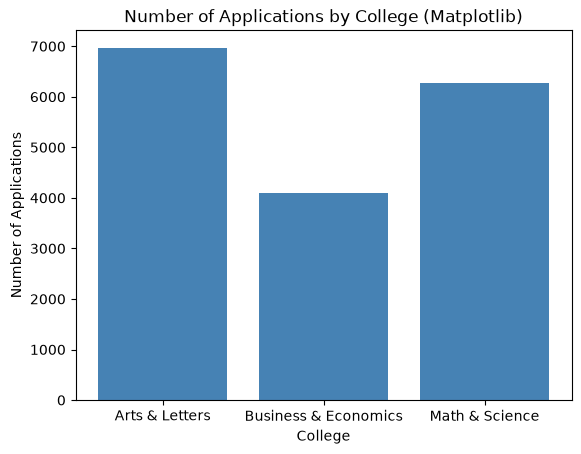

In [29]:
# 1a. Matplotlib bar chart
plt.bar(college_counts.index, 
        college_counts.values, 
        color='steelblue')
plt.title('Number of Applications by College (Matplotlib)')
plt.xlabel('College')
plt.ylabel('Number of Applications')
plt.show()

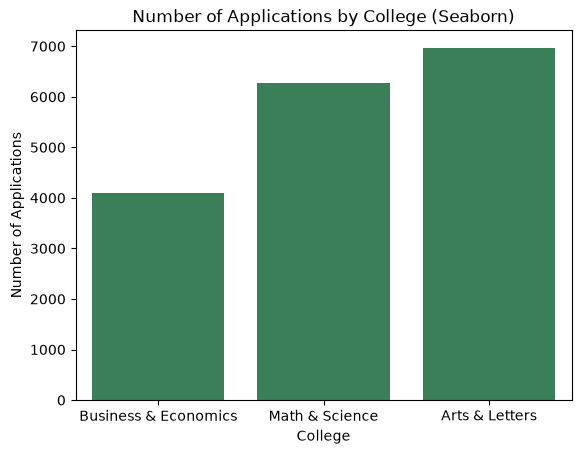

In [30]:
# 1b. Seaborn bar chart (countplot counts the applicants for each college by itself)
sns.countplot(data=df, 
              x='College', 
              color='seagreen')
plt.title('Number of Applications by College (Seaborn)')
plt.xlabel('College')
plt.ylabel('Number of Applications')
plt.show()

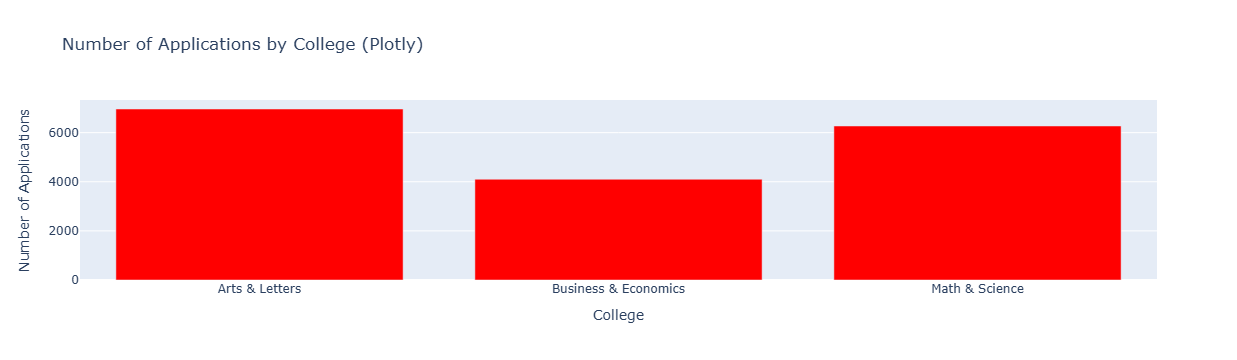

In [34]:
# 1c. Plotly bar chart (interactive: hover to see the exact count)
fig = px.bar(
    x=college_counts.index, 
    y=college_counts.values,
    color_discrete_sequence= ['red'],        
    labels={'x': 'College', 
            'y': 'Number of Applications'},
             title='Number of Applications by College (Plotly)',
)
fig.show()

**Answer:** Arts & Letters attracts the most applicants, with 6,964 of the 17,339 applications (about 40%). Math & Science is second with 6,272 (about 36%), and Business & Economics receives the fewest with 4,103 (about 24%).

## Task 02: Histogram – Distribution of SAT_ACT Scores

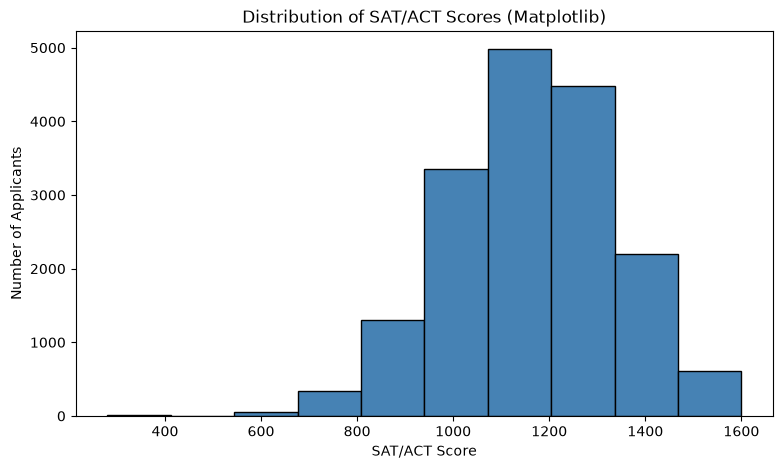

In [56]:
# 2a. Matplotlib histogram: splits the scores into 10 ranges
plt.figure(figsize=(9, 5))
plt.hist(df['SAT_ACT'], 
         bins=10, 
         color='steelblue', 
         edgecolor='black')
plt.title('Distribution of SAT/ACT Scores (Matplotlib)')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Number of Applicants')
plt.show()

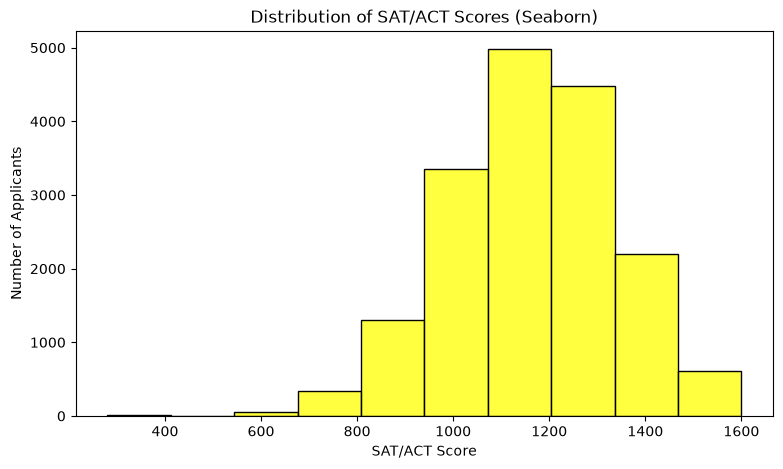

In [57]:
# 2b. Seaborn histogram
plt.figure(figsize=(9, 5))
sns.histplot(data=df, 
             x='SAT_ACT', 
             bins=10, 
             edgecolor='black', 
             color='yellow')
plt.title('Distribution of SAT/ACT Scores (Seaborn)')
plt.xlabel('SAT/ACT Score')
plt.ylabel('Number of Applicants')
plt.show()

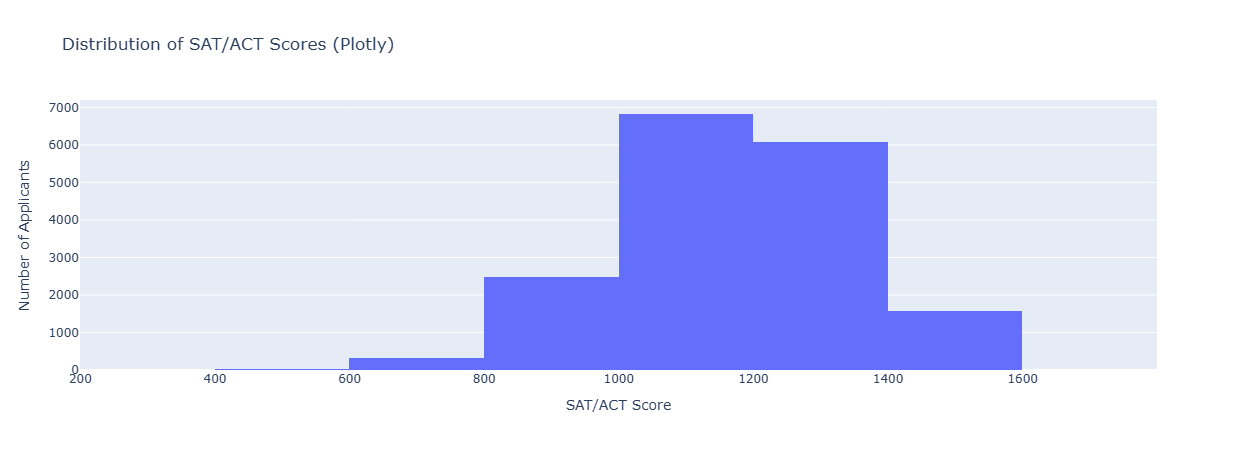

In [64]:
# 2c. Plotly histogram (hover over the tallest bar to see its range and count)
fig = px.histogram(
    df,
    x='SAT_ACT',
    nbins=10,
    title='Distribution of SAT/ACT Scores (Plotly)',
    width=800, height=450)

fig.update_layout(xaxis_title='SAT/ACT Score',
                  yaxis_title='Number of Applicants')
fig.show()

**Answer:** The most common SAT/ACT score range is about 1,000–1,199 (the tallest bar). Most scores fall between about 900 and 1,450, and a small number of very low scores create a longer tail on the left, so the distribution is slightly left-skewed.

## Task 03: Scatter Plot – Extracurricular_Hours vs SAT_ACT

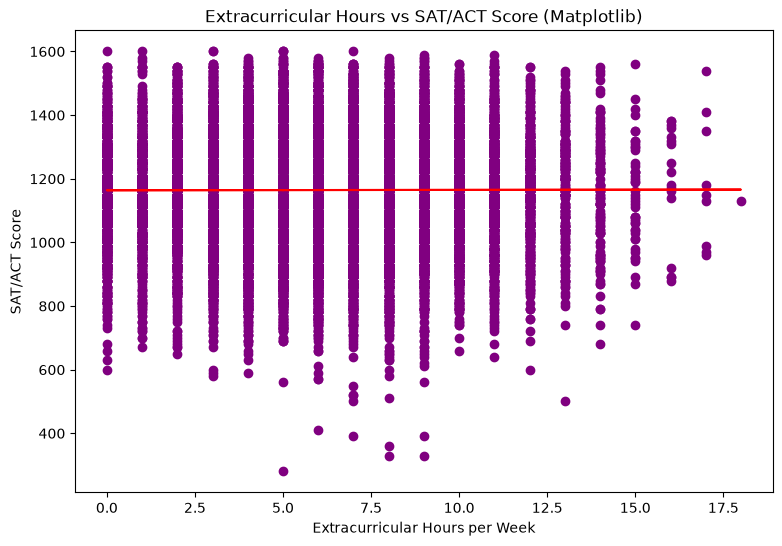

In [50]:
# 3a. Matplotlib scatter plot with a trendline
# X = Extracurricular Hours (independent variable), Y = SAT/ACT Score (dependent variable)
plt.figure(figsize=(9, 6))
plt.scatter(df['Extracurricular_Hours'], 
            df['SAT_ACT'], 
            color='purple')

# np.polyfit finds the slope and intercept of the best-fit straight line
m, b = np.polyfit(
    df['Extracurricular_Hours'], 
    df['SAT_ACT'], 1)
plt.plot(
    df['Extracurricular_Hours'], 
    m * df['Extracurricular_Hours'] + b, 
    color='red')
plt.title('Extracurricular Hours vs SAT/ACT Score (Matplotlib)')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')
plt.show()

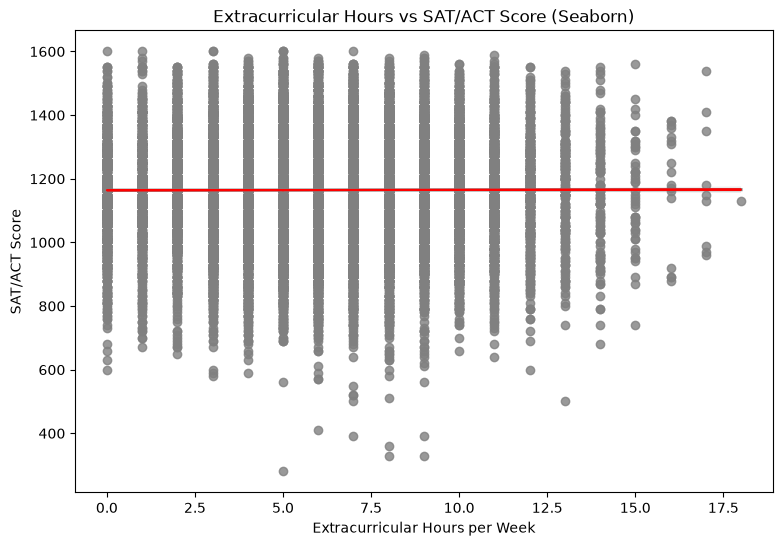

In [68]:
# 3b. Seaborn scatter plot (regplot draws the dots and the trendline together)
plt.figure(figsize=(9, 6))
sns.regplot(data=df, 
            x='Extracurricular_Hours',
            y='SAT_ACT', 
            color='gray',)
plt.plot(
    df['Extracurricular_Hours'], 
    m * df['Extracurricular_Hours'] + b, 
    color='red')
plt.title('Extracurricular Hours vs SAT/ACT Score (Seaborn)')
plt.xlabel('Extracurricular Hours per Week')
plt.ylabel('SAT/ACT Score')
plt.show()

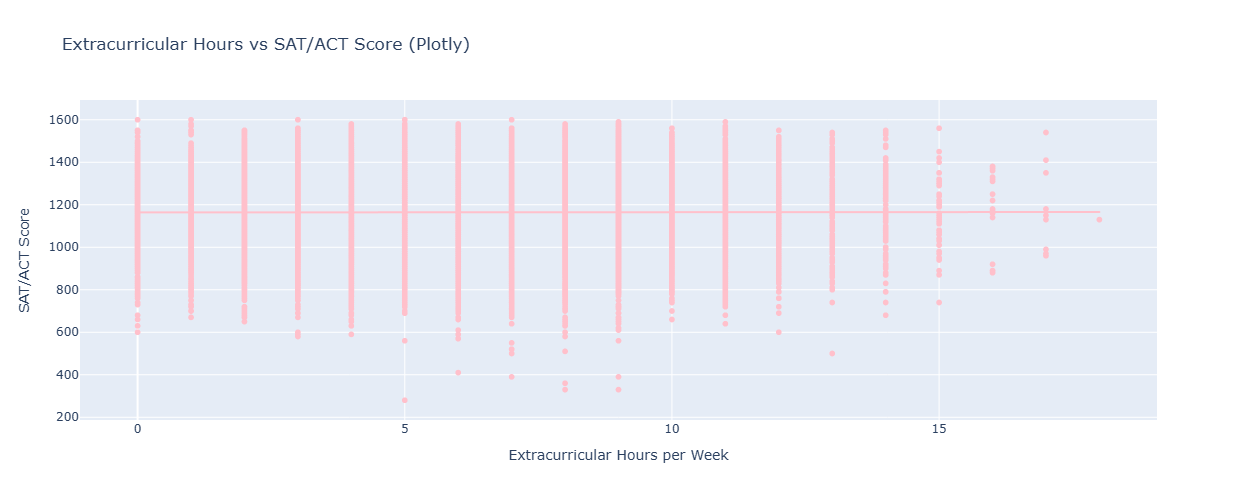

In [72]:
# 3c. Plotly scatter plot with a linear trendline (needs: pip install statsmodels)
fig = px.scatter(
    df, 
    x='Extracurricular_Hours', 
    y='SAT_ACT', 
    trendline='ols',
     color_discrete_sequence=['Pink'],
                 labels={'Extracurricular_Hours': 'Extracurricular Hours per Week', 
                         'SAT_ACT': 'SAT/ACT Score'},
                 title='Extracurricular Hours vs SAT/ACT Score (Plotly)',
                 width=850, 
                 height=500)
fig.show()

**Answer:** There is **no relationship** between extracurricular hours and SAT/ACT scores. The trendline is almost flat, and students with many hours score about the same as students with few hours. So spending more time on activities does not raise or lower test scores.

## Task 04: Data-Driven Insights

### Findings and recommendations:
### Key Findings

**Finding 1 – Arts & Letters has the highest demand.**
Arts & Letters receives about 40% of all applications (6,964), while Business & Economics receives only about 24% (4,103). Application volume is not balanced across the three colleges.

**Finding 2 – Most applicants score in the middle range, and admitted students score higher.**
The most common score range is about 1,000–1,199. Admitted applicants have an average SAT/ACT score of about 1,286, compared with about 1,111 for applicants who were not admitted, so test scores are an important part of admission decisions.

**Finding 3 – Extracurricular hours are not related to test scores.**
The flat trendline in Task 03 shows that students with many extracurricular hours score about the same as students with few hours.

### Recommendations
1. **Balance recruitment.** Put more recruitment effort (school visits, program marketing, scholarships) into Business & Economics to raise its application numbers, and plan more reviewers for Arts & Letters, which receives the most applications.
2. **Plan around the typical applicant.** Since most applicants score about 1,000–1,199, use this range to plan first-year course sections, tutoring, and academic support.
3. **Review extracurriculars separately.** Because extracurricular hours are not tied to test scores, admissions should evaluate them as a separate factor to find well-rounded applicants that test scores alone would miss.